In [2]:
import random
import time
import h5py
import torch
import os
import numpy as np
import matplotlib.pyplot as plt
import model.Spectra_MAE as spectra_mae


def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True


def show_spectra(y):
    plt.figure(figsize=(5, 3), dpi=100)
    plt.plot(y)
    plt.show()

def prepare_model(chkpt_dir, arch='spectraMAE_base_patch100'):
    model = getattr(spectra_mae, arch)()
    checkpoint = torch.load(chkpt_dir, map_location='cuda:0')
    msg = model.load_state_dict(checkpoint)
    return model

def model_inference(y, model_mae):
    spectra_tensor = torch.from_numpy(y).view(1, -1).float()
    spectra_tensor = spectra_tensor.view(1, 1, spectra_tensor.shape[-1])
    loss, pred, mask = model_mae(spectra_tensor, mask_ratio=0.50)
    pred = model_mae.unpatchify(pred)
    pred = pred.detach().numpy()
    pred = pred.reshape(spectra_tensor.shape[-1], )
    return pred

def model_inference_batch(y, model_mae, batch_size=64):
    preds = []
    device = next(model_mae.parameters()).device
    spectra_tensor = torch.from_numpy(y).float().to(device)
    
    if spectra_tensor.dim() == 2:
        spectra_tensor = spectra_tensor.unsqueeze(1) 
    for i in range(0, spectra_tensor.shape[0], batch_size):
        batch = spectra_tensor[i:i+batch_size]
        loss, pred, mask = model_mae(batch, mask_ratio=0.50)
        pred = model_mae.unpatchify(pred)
        pred = pred.detach().cpu().numpy()
        pred = pred.squeeze(1)
        preds.append(pred)
    
    return np.vstack(preds)


def calculate_metrics(spec_denoised, spec_gt):
    x = np.array(spec_denoised)
    y = np.array(spec_gt)
    
    rmse = np.sqrt(np.mean((x - y) ** 2))
    snr = 10 * np.log10(np.sum(y ** 2) / np.sum((x - y) ** 2) + 1e-8)

    inner_product = np.dot(x, y)
    norms = np.linalg.norm(x) * np.linalg.norm(y)
    sad = np.arccos(np.clip(inner_product / norms, -1.0, 1.0))

    pcc = np.corrcoef(x, y)[0, 1]
    
    sss = (1-sad) * pcc
    
    return snr, rmse, sss


def test(
    input_h5_path: str,
    output_h5_path: str,
    chkpt_dir: str,
    arch: str = 'spectraMAE_base_ss1600_ps2',
    batch_size: int = 64,
    seed: int = 615
):
    """
    加载数据并执行模型批量推理，将结果保存为 H5 文件。

    参数:
        input_h5_path (str): 输入的测试数据 H5 文件路径。
        output_h5_path (str): 推理结果 (denoised) 保存的 H5 文件路径。
        chkpt_dir (str): 模型权重文件 (.pth) 的路径。
        arch (str): 模型架构名称。
        batch_size (int): 推理时的批量大小。
        seed (int): 随机种子，确保结果可复现。
        
    返回:
        numpy.ndarray: 模型的预测结果数组。
    """
    # 1. 初始化
    seed_everything(seed)

    # 2. 加载数据
    with h5py.File(input_h5_path, 'r') as f:
        y = f['noisy'][:]
        # 注意：原代码中读取了 gt 但未使用，如果后续需要计算指标，可在此处同时返回 gt
        # gt = f['gt'][:] 

    # 3. 准备模型
    model_mae = prepare_model(chkpt_dir=chkpt_dir, arch=arch)
    model_mae.eval()

    # 4. 执行推理
    time_start = time.time()
    pred = model_inference_batch(y, model_mae, batch_size=batch_size)
    time_end = time.time()
    

    # 5. 保存结果
    # 确保输出目录存在，避免路径错误导致保存失败
    os.makedirs(os.path.dirname(output_h5_path), exist_ok=True)
    with h5py.File(output_h5_path, 'w') as f:
        f.create_dataset('denoised', data=pred)
        
    return pred

/home/slurmusers/moria/.conda/envs/fast2peak/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/slurmusers/moria/.conda/envs/fast2peak/lib/python3.12/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


### Simu1024测试代码

(1024, 1600)
<All keys matched successfully>


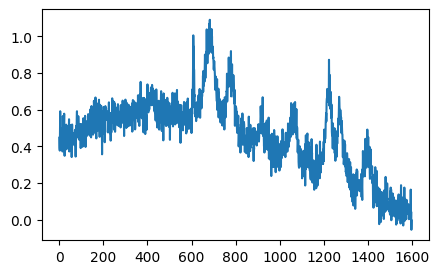

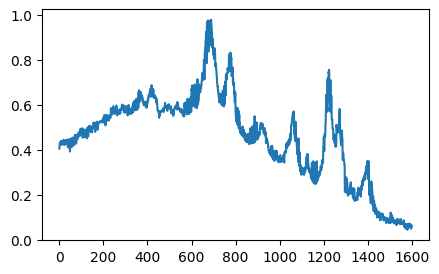

In [2]:
seed_everything(42)

import h5py

with h5py.File(r'D:\AResearchwork\codes\fast2peak\datasets\test\simu1024.h5', 'r') as f:
    data_h5 = f['noisy'][:]
print(data_h5.shape)

y = data_h5[5]

chkpt_dir = r'D:\AResearchwork\codes\fast2peak\smae\experiments\smae on simu ps2\epoch_1000_final.pth'
model_mae = prepare_model(chkpt_dir=chkpt_dir, arch='spectraMAE_base_ss1600_ps2')
model_mae.eval()

pred = model_inference(y, model_mae)

show_spectra(y)
show_spectra(pred)


(1024, 1600)
<All keys matched successfully>


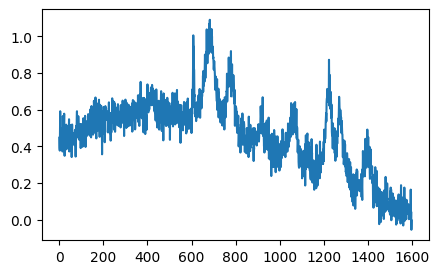

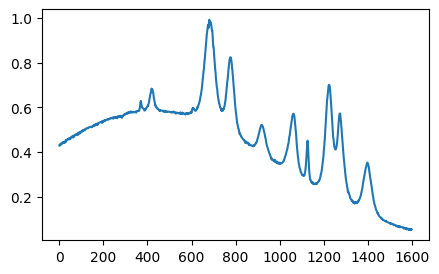

In [3]:
seed_everything(42)

import h5py

with h5py.File(r'D:\AResearchwork\codes\fast2peak\datasets\test\simu1024.h5', 'r') as f:
    data_h5 = f['noisy'][:]
print(data_h5.shape)

y = data_h5[5]

chkpt_dir = r'experiments/smae with train.h5 ss1600 ps2/epoch_500.pth'
model_mae = prepare_model(chkpt_dir=chkpt_dir, arch='spectraMAE_base_ss1600_ps2')
model_mae.eval()

pred = model_inference(y, model_mae)

show_spectra(y)
show_spectra(pred)


In [ ]:
INPUT_PATH = '/home/slurmusers/moria/codes/fast2peak_v2/datasets/test/Simu.h5'
OUTPUT_PATH = '/home/slurmusers/moria/codes/fast2peak_v2/experiments/smae raw ps2/simu1024.h5'
CHECKPOINT = 'experiments/smae with train.h5 ss1600 ps2/epoch_500.pth'

predictions = test(
    input_h5_path=INPUT_PATH,
    output_h5_path=OUTPUT_PATH,
    chkpt_dir=CHECKPOINT,
    arch='spectraMAE_base_ss1600_ps2',
    batch_size=64,
    seed=615
)

(1024, 1600)
<All keys matched successfully>
Inference time: 35.95 seconds
(1024, 1600)
Final Results -> SNR: 29.83 | RMSE: 0.0119 | SSS: 0.9522


In [14]:
seed_everything(42)

import h5py

with h5py.File(r'D:\AResearchwork\codes\fast2peak\datasets\test\simu1024.h5', 'r') as f:
    data_h5 = f['noisy'][:]
    data_gt = f['gt'][:]
print(data_h5.shape)

y = data_h5
gt = data_gt

chkpt_dir = r'D:\AResearchwork\codes\fast2peak\smae\experiments\smae with train.h5\epoch_1000_final.pth'
model_mae = prepare_model(chkpt_dir=chkpt_dir, arch='spectraMAE_base_ss1600_ps100')
model_mae.eval()

time_start = time.time()
pred = model_inference_batch(y, model_mae)
time_end = time.time()
print(f"Inference time: {time_end - time_start:.2f} seconds")
print(pred.shape)
with h5py.File(r'D:\AResearchwork\codes\fast2peak\experiments\smae raw ps100\simu1024.h5', 'w') as f:
    f.create_dataset('denoised', data=pred)
# show_spectra(y)
# show_spectra(pred)

all_metrics = np.array([calculate_metrics(gt[i], pred[i]) for i in range(y.shape[0])])

avg_snr = np.round(np.mean(all_metrics[:, 0]), 2)
avg_rmse = np.round(np.mean(all_metrics[:, 1]), 4)
avg_sss = np.round(np.mean(all_metrics[:, 2]), 4)

print(f"Final Results -> SNR: {avg_snr} | RMSE: {avg_rmse} | SSS: {avg_sss}")

(1024, 1600)
<All keys matched successfully>
Inference time: 1.00 seconds
(1024, 1600)
Final Results -> SNR: 11.17 | RMSE: 0.0994 | SSS: 0.4872


In [8]:
seed_everything(42)

import h5py
import time
with h5py.File(r'D:\AResearchwork\codes\fast2peak\datasets\test\electro.h5', 'r') as f:
    data_h5 = f['noisy'][:]
    data_gt = f['gt'][:]
print(data_h5.shape)

y = data_h5
gt = data_gt

chkpt_dir = r'D:\AResearchwork\codes\fast2peak\smae\experiments\smae with train.h5 ss1600 ps2\epoch_500.pth'
model_mae = prepare_model(chkpt_dir=chkpt_dir, arch='spectraMAE_base_ss1600_ps2')
model_mae.eval()

time_start = time.time()
pred = model_inference_batch(y, model_mae)
time_end = time.time()
print(f"Inference time: {time_end - time_start:.2f} seconds")
print(pred.shape)
with h5py.File(r'D:\AResearchwork\codes\fast2peak\experiments\smae raw ps2\electro.h5', 'w') as f:
    f.create_dataset('denoised', data=pred)
# show_spectra(y)
# show_spectra(pred)

all_metrics = np.array([calculate_metrics(gt[i], pred[i]) for i in range(y.shape[0])])

avg_snr = np.round(np.mean(all_metrics[:, 0]), 2)
avg_rmse = np.round(np.mean(all_metrics[:, 1]), 4)
avg_sss = np.round(np.mean(all_metrics[:, 2]), 4)

print(f"Final Results -> SNR: {avg_snr} | RMSE: {avg_rmse} | SSS: {avg_sss}")

(32, 1600)
<All keys matched successfully>
Inference time: 1.00 seconds
(32, 1600)
Final Results -> SNR: 24.76 | RMSE: 0.0195 | SSS: 0.9333


#### 多肽测试

In [3]:
seed_everything(42)

import h5py
import time
with h5py.File('/home/slurmusers/moria/codes/fast2peak_v2/datasets/duotai.h5', 'r') as f:
    data_h5 = f['noisy'][:]
    # data_gt = f['gt'][:]
print(data_h5.shape)

y = data_h5
# gt = data_gt

chkpt_dir = '/home/slurmusers/moria/codes/fast2peak_v2/smae/experiments/smae with duotai ss2048 ps16/epoch_1000_final.pth'
model_mae = prepare_model(chkpt_dir=chkpt_dir, arch='spectraMAE_base_ss2048_ps16')
model_mae.eval()

time_start = time.time()
pred = model_inference_batch(y, model_mae)
time_end = time.time()
print(f"Inference time: {time_end - time_start:.2f} seconds")
print(pred.shape)
with h5py.File('/home/slurmusers/moria/codes/fast2peak_v2/smae/experiments/smae with duotai ss2048 ps16/duotai.h5', 'w') as f:
    f.create_dataset('denoised', data=pred)
# show_spectra(y)
# show_spectra(pred)


(88, 2048)


RuntimeError: Attempting to deserialize object on a CUDA device but torch.cuda.is_available() is False. If you are running on a CPU-only machine, please use torch.load with map_location=torch.device('cpu') to map your storages to the CPU.

#### smae原版

<All keys matched successfully>


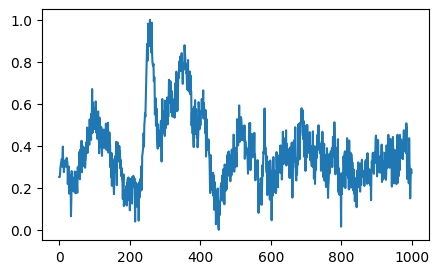

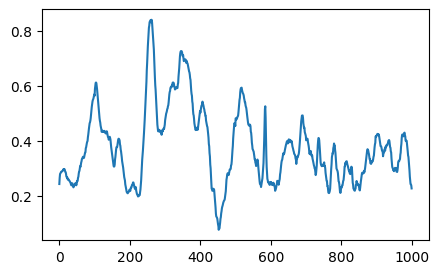

In [ ]:
seed_everything(42)

data = np.load(r'D:\AResearchwork\codes\fast2peak\smae\datasets\X_finetune.npy')
y = data[0]

chkpt_dir = r'experiments/smae_raw/epoch_500_final.pth'
model_mae = prepare_model(chkpt_dir=chkpt_dir, arch='spectraMAE_base_ss1000_ps100')
model_mae.eval()

pred = model_inference(y, model_mae)

show_spectra(y)
show_spectra(pred)

